# Apache SpamAssassin Spam Classifier

In [15]:
from pathlib import Path
import splitfolders
import pandas as pd
import sklearn
import tarfile
import shutil
import os
import re

## Data download and Inspection

The following script will download the dataset corpus to data/spam_assassin_corpus

In [16]:
!rm -r data/
!wget -r -q -np -nd \
    -P ./data/spam_assassin_corpus \
    -A "*.bz2,readme.html" \
    -X /old/publiccorpus/obsolete/ \
    https://spamassassin.apache.org/old/publiccorpus/

Now that the data is downloaded, we will need to unzip it.

In [17]:
for filename in os.listdir('data/spam_assassin_corpus'):
    if filename.endswith('.tar.bz2'):
        with tarfile.open(f'data/spam_assassin_corpus/{filename}', 'r:bz2') as f:
            f.extractall(f'data/{filename[:-8]}')


base_dir = Path('data')

for parent_dir in base_dir.iterdir():
    if not parent_dir.is_dir():
        continue

    # get subfolders in the parent dir
    child_dirs = [d for d in parent_dir.iterdir() if d.is_dir()]

    if not child_dirs:
        continue

    # for each child dir, move the files to the parent dir
    for child_dir in child_dirs:
        for file in child_dir.iterdir():
            if file.name == "cmds":
                continue
            shutil.move(str(file), str(parent_dir))

        if not any(child_dir.iterdir()):
            child_dir.rmdir()
        else:
            shutil.rmtree(child_dir)

# take out the readme.html file from the spam_assassin_corpus folder and move it to the data folder
shutil.move('data/spam_assassin_corpus/readme.html', 'data/readme.html')    
shutil.rmtree('data/spam_assassin_corpus')

/var/folders/cl/gj5wytzj6ns_nk7qgjq7v7q40000gn/T/ipykernel_90556/2308669284.py:4: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  f.extractall(f'data/{filename[:-8]}')


Let's inspect one of the data file

In [18]:
sample_filename = os.listdir(base_dir / '20021010_easy_ham')[0]
sample_file = base_dir / '20021010_easy_ham' / sample_filename
with open(sample_file, 'r', encoding='latin-1') as f:
    text = f.read()
print(f"Sample file: {sample_filename}\n")
print(text)

Sample file: 2170.78c282a5e417d6d231dc75aa8588ebb7

From rssfeeds@jmason.org  Mon Sep 30 13:43:46 2002
Return-Path: <rssfeeds@example.com>
Delivered-To: yyyy@localhost.example.com
Received: from localhost (jalapeno [127.0.0.1])
	by jmason.org (Postfix) with ESMTP id AE79816F16
	for <jm@localhost>; Mon, 30 Sep 2002 13:43:46 +0100 (IST)
Received: from jalapeno [127.0.0.1]
	by localhost with IMAP (fetchmail-5.9.0)
	for jm@localhost (single-drop); Mon, 30 Sep 2002 13:43:46 +0100 (IST)
Received: from dogma.slashnull.org (localhost [127.0.0.1]) by
    dogma.slashnull.org (8.11.6/8.11.6) with ESMTP id g8U81fg21359 for
    <jm@jmason.org>; Mon, 30 Sep 2002 09:01:41 +0100
Message-Id: <200209300801.g8U81fg21359@dogma.slashnull.org>
To: yyyy@example.com
From: gamasutra <rssfeeds@example.com>
Subject: Priceless Rubens works stolen in raid on mansion
Date: Mon, 30 Sep 2002 08:01:41 -0000
Content-Type: text/plain; encoding=utf-8
Lines: 6
X-Spam-Status: No, hits=-527.4 required=5.0
	tests=AWL,DATE_IN

Now that we have seen the email format, we will check how many such files are there.

In [19]:
data_info = pd.DataFrame(columns=['folder', 'type', 'files_count'])
data_info['folder'] = os.listdir(base_dir)
data_info.drop(data_info[data_info['folder'] == 'readme.html'].index, inplace=True)
data_info['type'] = data_info['folder'].apply(lambda x: 'spam' if 'spam' in x else 'ham')
data_info['files_count'] = data_info['folder'].apply(lambda x: len(os.listdir(base_dir / x)))

total_files = data_info['files_count'].sum()
total_spam_files = data_info[data_info['type'] == 'spam']['files_count'].sum()
total_ham_files = data_info[data_info['type'] == 'ham']['files_count'].sum()

data_info

,folder,type,files_count
0,20030228_easy_ham_2,ham,1400
1,20030228_hard_ham,ham,250
2,20030228_spam,spam,500
4,20030228_easy_ham,ham,2500
5,20030228_spam_2,spam,1397
6,20021010_spam,spam,501
7,20021010_hard_ham,ham,250
8,20021010_easy_ham,ham,2551
9,20050311_spam_2,spam,1396


In [20]:
print(f"Total files: {total_files}")
print(f"Total spam files: {total_spam_files}")
print(f"Total ham files: {total_ham_files}")
print(f"Percentage of spam: {total_spam_files / total_files * 100:.2f}%")

Total files: 10745
Total spam files: 3794
Total ham files: 6951
Percentage of spam: 35.31%


Wow, there is some dataset imbalance. Only 35% of the files are spam

## Train-Test Split

We will use a 80-20 split. For each folder in data, we will do a 80-20 split of the folder. The split will be saved on data_split folder.

Before we make the train test split, we will make some preprocessing in the whole dataset that will not cause information loss and test data leakage. These are the preprocessing that will be done:
- strip email headers
- convert email to lowercase,
- replace urls with 'URL',
- replace numbers with 'NUMBER',
- trim word endings

In [21]:
# Turns out the model performs better when emails are not preprocessed.


# for folder in base_dir.iterdir():
#     if not folder.is_dir():
#         continue

#     for file in folder.iterdir():
#         if not file.is_file():
#             continue

#         with open(file, 'r', encoding='latin-1') as f:
#             text = f.read()

#         # strip email headers
#         # text = text.split('\n\n', 1)[-1]
        
#         # convert email to lowercase
#         text = text.lower()

#         # replace urls with 'URL'
#         # text = re.sub(r'http\S+|www\S+|https\S+', 'URL', text)

#         # replace numbers with 'NUMBER'
#         text = re.sub(r'\d+', 'NUMBER', text)

#         # trim word endings
#         text = re.sub(r'\b(\w+)(ing|ed|s)\b', r'\1', text)

#         with open(file, 'w', encoding='latin-1') as f:
#             f.write(text)        

In [22]:
shutil.rmtree('data_split')
splitfolders.ratio('data', output='data_split', 
            seed=42, ratio=(.8, 0.0, 0.20), group_prefix=None, shuffle=True)

In [23]:
train_files = []
for folder in Path('data_split/train').iterdir():
    if folder.is_dir():
        train_files.extend([f for f in Path(folder).iterdir() if f.is_file()])

test_files = []
for folder in Path('data_split/test').iterdir():
    if folder.is_dir():
        test_files.extend([f for f in Path(folder).iterdir() if f.is_file()])

## Data Preparation Pipeline

The word processing and turning the email into sparse vector should be done here. We will only touch the training set now on until we reach the test phase.

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(input='filename', lowercase=True, stop_words='english', encoding='latin-1', max_features=10000)
X_train = vectorizer.fit_transform(train_files)
X_test = vectorizer.transform(test_files)

y_train = [1 if 'spam' in str(f) else 0 for f in train_files]
y_test = [1 if 'spam' in str(f) else 0 for f in test_files]

X_train.shape, X_test.shape, len(y_train), len(y_test)

((8593, 10000), (2152, 10000), 8593, 2152)

## Modeling

### Logistic Regression

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report

log_clf = LogisticRegression()
log_clf.fit(X_train, y_train)

report = classification_report(y_test, log_clf.predict(X_test), target_names=['ham', 'spam'])
print(report)

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99      1391
        spam       0.98      0.98      0.98       761

    accuracy                           0.98      2152
   macro avg       0.98      0.98      0.98      2152
weighted avg       0.98      0.98      0.98      2152



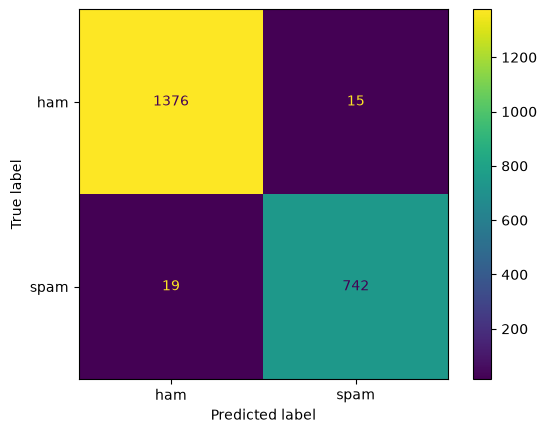

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, log_clf.predict(X_test), labels=log_clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['ham', 'spam'])
disp.plot()
plt.show()

### SVM Classifier

In [27]:
from sklearn import svm

svm_clf = svm.SVC(kernel='linear')
svm_clf.fit(X_train, y_train)

report = classification_report(y_test, svm_clf.predict(X_test), target_names=['ham', 'spam'])
print(report)

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99      1391
        spam       0.99      0.99      0.99       761

    accuracy                           0.99      2152
   macro avg       0.99      0.99      0.99      2152
weighted avg       0.99      0.99      0.99      2152



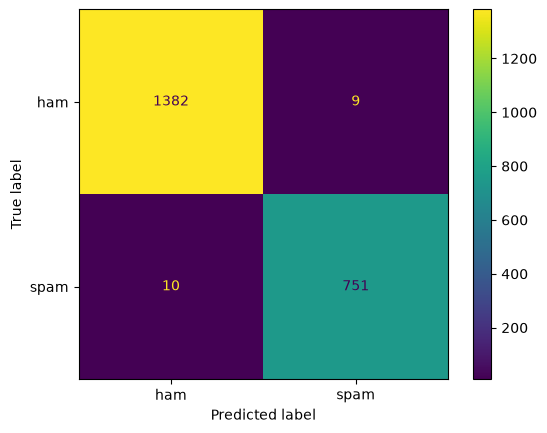

In [28]:
cm = confusion_matrix(y_test, svm_clf.predict(X_test), labels=svm_clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['ham', 'spam'])
disp.plot()
plt.show()

### Random Forest Classifier

In [29]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

report = classification_report(y_test, rf_clf.predict(X_test), target_names=['ham', 'spam'])
print(report)

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99      1391
        spam       0.99      0.99      0.99       761

    accuracy                           0.99      2152
   macro avg       0.99      0.99      0.99      2152
weighted avg       0.99      0.99      0.99      2152



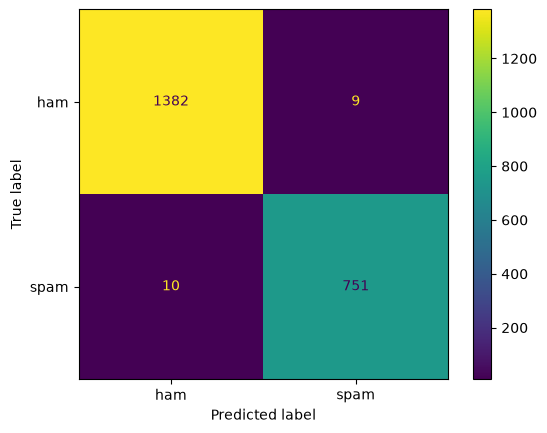

In [30]:
cm = confusion_matrix(y_test, svm_clf.predict(X_test), labels=svm_clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['ham', 'spam'])
disp.plot()
plt.show()